# Chapter 76: Commitment, Credibility, Sovereign Risk, and Conflict

This notebook reruns four worked examples from the chapter: escrow that makes a contract penalty credible, a sovereign bond priced on beliefs about repayment, the inflation bias of discretionary monetary policy, and a peace deal undone by shifting power. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def game_tree(ax, nodes, edges, highlight_edges=None, xlabel="Stage", ylabel="Branch"):
    """Small extensive-form tree.

    ``nodes`` maps id -> (x, y, text); ``edges`` is a list of (from, to, action label).
    ``highlight_edges`` is a set of (from, to) drawn thick in teal (the equilibrium path).
    """
    highlight_edges = set(highlight_edges or [])
    for a, b, act in edges:
        (x0, y0, _), (x1, y1, _) = nodes[a], nodes[b]
        hot = (a, b) in highlight_edges
        ax.plot([x0, x1], [y0, y1], color=PALETTE["teal"] if hot else PALETTE["grey"], linewidth=3 if hot else 1.4)
        ax.annotate(act, ((x0 + x1) / 2, (y0 + y1) / 2), ha="center", va="center", fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none"})
    for x, y, text in nodes.values():
        ax.scatter([x], [y], s=40, color=PALETTE["ink"], zorder=4)
        if text:
            ax.annotate(text, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=LABEL_SIZE)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def escrow_supplier(price, quality_cost, penalty, suit_cost, p, mechanism):
    """Supplier's choice when a defect penalty is collected by lawsuit or by escrow.

    Principle: credible-commitment-and-threats. Book (ch076): price 80, quality cost 18, penalty 45,
    suit cost 52: suing nets 45 - 52 = -7, so the lab forgives and low quality pays 80 > 62. Under escrow
    low quality yields 80 - 45p (35 at p = 1, 53 at p = 0.60); high quality wins when p >= 18/45 = 0.40.
    """
    high = price - quality_cost
    sue_net = penalty - suit_cost
    sues = sue_net > 0
    if mechanism == "escrow":
        low = price - penalty * p
    else:
        low = price - (penalty * p if sues else 0.0)
    return {"high": high, "low": low, "sue_net": sue_net, "sues": sues, "high_quality": high >= low,
            "tie": abs(high - low) < 1e-9, "p_star": quality_cost / penalty}


def risky_bond_price(face, p_default, r, need, output, penalty):
    """Zero-recovery bond price q = (1 - p_d) face / (1 + r), funding test and repayment incentive.

    Principle: credible-commitment. Book (ch076): 0.70(150)/1.08 = 97.22 < 120; 0.92(150)/1.08 = 127.78;
    repay 180 - 150 = 30 against default 180 - 165 = 15 (repay) or 180 - 100 = 80 (default).
    """
    q = (1 - p_default) * face / (1 + r)
    repay, default = output - face, output - penalty
    return {"q": q, "funded": q >= need, "repay": repay, "default": default, "credible": repay > default,
            "tie": repay == default}


def barro_gordon(k, b, pi_e=0.0):
    """Discretionary reaction pi = b(pi^e + k)/(1 + b), equilibrium pi = b k, and losses.

    Loss L = pi^2 + b[(y - y^n) - k]^2 with y - y^n = pi - pi^e. Principle: time-inconsistency.
    Book (ch076, k 2, b 0.5): reaction to pi^e = 0 is 2/3; pi = 1; L_D = 1 + 0.5(4) = 3; L_C = 0.5(4) = 2.
    """
    reaction = b * (pi_e + k) / (1 + b)
    pi_d = b * k
    loss_c = b * k * k
    loss_d = pi_d * pi_d + loss_c
    return {"reaction": reaction, "pi_d": pi_d, "loss_d": loss_d, "loss_c": loss_c, "bias_cost": loss_d - loss_c}


def war_payoffs(prize, cost_a, cost_b, p_a1, p_a2, offer_a, guarantor):
    """War payoffs w = p(prize) - cost now and later, and whether an offer survives the power shift.

    Principle: commitment-problem-theory-of-war. Book (ch076): w_A(1) = 0.65(100) - 15 = 50,
    w_B(1) = 0.35(100) - 20 = 15, w_A(2) = 5, w_B(2) = 60; the 55 to 45 deal fails without a guarantor
    and holds with a 20 penalty because 60 - 20 = 40 < 45.
    """
    wa1, wb1 = p_a1 * prize - cost_a, (1 - p_a1) * prize - cost_b
    wa2, wb2 = p_a2 * prize - cost_a, (1 - p_a2) * prize - cost_b
    offer_b = prize - offer_a
    revise = wb2 - guarantor
    accept_now = offer_a > wa1 and offer_b > wb1
    return {"wa1": wa1, "wb1": wb1, "wa2": wa2, "wb2": wb2, "range": (wa1, prize - wb1), "offer_b": offer_b,
            "revise": revise, "accept_now": accept_now, "honors": revise < offer_b, "tie": revise == offer_b,
            "survives": accept_now and revise < offer_b}


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(escrow_supplier=escrow_supplier)


finance = SimpleNamespace(risky_bond_price=risky_bond_price)


macro = SimpleNamespace(barro_gordon=barro_gordon)


games = SimpleNamespace(war_payoffs=war_payoffs)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'credible-commitment-and-threats': {'price': 80,
                                     'quality_cost': 18,
                                     'penalty': 45,
                                     'suit_cost': 52,
                                     'sue_net': -7,
                                     'high': 62,
                                     'low_lawsuit': 80,
                                     'low_escrow_certain': 35,
                                     'p_star': 0.4,
                                     'p_alt': 0.6,
                                     'low_alt': 53},
 'credible-commitment': {'face': 150,
                         'r': 0.08,
                         'need': 120,
                         'pd': 0.3,
                         'q': 97.22,
                         'pd_low': 0.08,
                         'q_low': 127.78,
                         'output': 180,
                         'repay': 30,
                         'penalty': 165,
                         'default': 15,
                         'penalty_weak': 100,
                         'default_weak': 80},
 'time-inconsistency': {'k': 2,
                        'b': 0.5,
                        'reaction_0': 0.6666666666666666,
                        'pi_d': 1,
                        'L_D': 3,
                        'L_C': 2},
 'commitment-problem-theory-of-war': {'prize': 100,
                                      'cost_A': 15,
                                      'cost_B': 20,
                                      'pA1': 0.65,
                                      'pA2': 0.2,
                                      'wA1': 50,
                                      'wB1': 15,
                                      'wA2': 5,
                                      'wB2': 60,
                                      'offer_A': 55,
                                      'guarantor': 20,
                                      'revise': 40,
                                      'range': (50, 85)},
 'constructed': {'credible-commitment-and-threats': {'p': [0.2]},
                 'credible-commitment': {'pd': [0.2], 'penalty': [150]},
                 'time-inconsistency': {'k': [0, 1, 3], 'b': [0.25, 1.0]},
                 'commitment-problem-theory-of-war': {'pA2': [0.4], 'guarantor': [10, 30]}}}


def escrow_picture(mech="lawsuit", p=1.0):
    b = BV["credible-commitment-and-threats"]
    res = public.escrow_supplier(b["price"], b["quality_cost"], b["penalty"], b["suit_cost"], p, mech)
    high, low = res["high"], res["low"]
    tie = res["tie"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    if mech == "lawsuit":
        nodes = {"S": (0, 0.5, "Supplier"), "H": (1, 0.85, "high: 62"), "L": (1, 0.2, "Lab"),
                 "sue": (2.3, 0.5, "sue: 35, lab -7"), "fg": (2.3, -0.05, "forgive: 80, lab 0")}
        edges = [("S", "H", "high"), ("S", "L", "low"), ("L", "sue", "sue"), ("L", "fg", "forgive")]
        hot = {("L", "fg"), ("S", "L")} if not res["high_quality"] else {("L", "fg"), ("S", "H")}
    else:
        nodes = {"S": (0, 0.5, "Supplier"), "H": (1, 0.85, "high: 62"), "L": (1, 0.2, "Check"),
                 "det": (2.3, 0.5, "caught: 35"), "miss": (2.3, -0.05, "missed: 80")}
        edges = [("S", "H", "high"), ("S", "L", "low"), ("L", "det", f"p = {num(p)}"),
                 ("L", "miss", f"1 - p = {num(1 - p)}")]
        hot = {("S", "H")} if res["high_quality"] else {("S", "L")}
    game_tree(ax1, nodes, edges, highlight_edges=hot, xlabel="Stage", ylabel="Branch")
    ax1.set_xlim(-0.2, 3.6)
    ax1.set_ylim(-0.2, 1.05)
    ax1.set_title("Lawsuit after delivery" if mech == "lawsuit" else "Escrow of 45", fontsize=12)
    ax2.bar([0, 1], [high, low], width=0.55,
            color=[PALETTE["teal"], PALETTE["terracotta"]])
    for x_, v in zip([0, 1], [high, low]):
        label(ax2, x_, v, num(v), col="ink", dx=0, dy=3, ha="center")
    ax2.set_xticks([0, 1], ["high quality", "low quality (expected)"])
    ax2.set_ylim(0, 100)
    ax2.set_xlabel("Supplier's choice")
    ax2.set_ylabel("Supplier's payoff")
    if tie:
        choice_txt = "Tie: indifferent at 62"
    else:
        choice_txt = "High quality" if res["high_quality"] else "Low quality"
    metrics = {"Lab's net from suing": num(res["sue_net"], 0), "Supplier, high quality": num(high),
               "Supplier, low quality (expected)": num(low), "Supplier's choice": choice_txt,
               "Deterrence threshold p": num(res["p_star"])}
    if mech == "lawsuit":
        steps = ["Lab's net from suing = 45 - 52 = -7, below 0 from forgiving, so it forgives",
                 "High quality: 80 - 18 = 62",
                 "Low quality: 80, because the penalty is never collected",
                 "62 < 80: low quality"]
        interp = ("Suing would win 45 but cost 52, so the lab's net is 45 - 52 = -7 and it forgives. The supplier "
                  "therefore compares 80 - 18 = 62 from high quality with 80 from low quality and cheats. "
                  f"Detection at {num(p)} changes nothing, because a detected defect still goes unpunished.")
    else:
        rel = "=" if tie else (">" if high > low else "<")
        steps = ["High quality: 80 - 18 = 62",
                 f"Low quality: 80 - 45 x {num(p)} = 80 - {num(45 * p)} = {num(low)}",
                 f"62 {rel} {num(low)}",
                 "Deterrence needs 62 >= 80 - 45p, so p >= 18 / 45 = 0.40"]
        if tie:
            verdict = ("the supplier is exactly indifferent; the book's weak inequality 62 >= 80 - 45p counts this "
                       "threshold as deterring")
        elif res["high_quality"]:
            verdict = f"high quality wins because {num(p)} is above the 0.40 threshold"
        else:
            verdict = f"low quality still pays because {num(p)} is below the 0.40 threshold"
        interp = (f"With 45 held in escrow, a detected defect transfers the deposit automatically. Low quality "
                  f"yields 80 - 45 x {num(p)} = {num(low)} against 62 from high quality, so {verdict}.")
    alt = (f"Left: the game tree under {'a lawsuit' if mech == 'lawsuit' else 'escrow'} with the equilibrium path "
           f"highlighted. Right: the supplier's payoff from high quality, 62, against {num(low)} from low quality.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bond_picture(pd=0.30, penalty=165):
    b = BV["credible-commitment"]
    res = finance.risky_bond_price(b["face"], pd, b["r"], b["need"], b["output"], penalty)
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.bar([0], [res["q"]], width=0.5, color=PALETTE["teal" if res["funded"] else "navy"])
    label(ax1, 0.27, res["q"] / 2, f"q = {num(res['q'])}", col="ink", dx=4, dy=0, ha="left", va="center")
    hline(ax1, b["need"], "funding need 120", col="terracotta", style="solid", x_frac=0.55, lw=2)
    ax1.set_xlim(-0.6, 1.2)
    ax1.set_ylim(0, 170)
    ax1.set_xticks([0], [f"default probability {num(pd)}"])
    ax1.set_xlabel("Investors' belief")
    ax1.set_ylabel("Bond price q")
    ax2.bar([0, 1], [res["repay"], res["default"]], width=0.55, color=[PALETTE["teal"], PALETTE["terracotta"]])
    for x_, v in zip([0, 1], [res["repay"], res["default"]]):
        label(ax2, x_, v, num(v, 0), col="ink", dx=0, dy=3, ha="center")
    ax2.set_xticks([0, 1], ["repay: 180 - 150", f"default: 180 - {penalty}"])
    ax2.set_ylim(0, 100)
    ax2.set_xlabel("Government's option next period")
    ax2.set_ylabel("Government's payoff")
    if res["tie"]:
        cred = "Tie: indifferent"
    else:
        cred = "yes" if res["credible"] else "no"
    metrics = {"Bond price q": num(res["q"]), "Funded (q at least 120)": "yes" if res["funded"] else "no",
               "Repay payoff": num(res["repay"], 0), "Default payoff": num(res["default"], 0),
               "Repayment credible": cred}
    rel = ">=" if res["funded"] else "<"
    rr = "=" if res["tie"] else (">" if res["credible"] else "<")
    steps = [f"q = (1 - {num(pd)}) x 150 / 1.08 = {num((1 - pd) * 150)} / 1.08 = {num(res['q'])}",
             f"{num(res['q'])} {rel} 120: {'funded' if res['funded'] else 'not funded'}",
             "Repay: 180 - 150 = 30",
             f"Default: 180 - {penalty} = {num(res['default'], 0)}",
             f"30 {rr} {num(res['default'], 0)}"]
    if res["tie"]:
        tail = ("Repaying and defaulting both leave 30, so the promise is not strictly credible: the government "
                "is indifferent.")
    elif res["credible"]:
        tail = f"Repaying leaves 30 against {num(res['default'], 0)} from default, so the promise is credible."
    else:
        tail = (f"Default leaves {num(res['default'], 0)}, more than the 30 from repaying, so the promise is not "
                f"credible and investors should not hold a low default belief.")
    interp = (f"At default probability {num(pd)}, the bond is worth (1 - {num(pd)}) x 150 / 1.08 = {num(res['q'])}, "
              f"{'enough' if res['funded'] else 'not enough'} to raise 120. {tail}")
    alt = (f"Left: bond price {num(res['q'])} against a funding need of 120. Right: repayment payoff 30 against a "
           f"default payoff of {num(res['default'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def policy_picture(k=2, b=0.5):
    res = macro.barro_gordon(k, b)
    pe = np.linspace(0, 5, 50)
    fig, ax = new_figure()
    ax.plot(pe, pe, color=PALETTE["grey"], linewidth=1.4, linestyle="dashed")
    ax.plot(pe, b * (pe + k) / (1 + b), color=PALETTE["navy"], linewidth=2.4)
    label(ax, 4.9, 4.9, "pi = pi^e", col="grey", dx=-4, dy=-6, ha="right", va="top")
    label(ax, 4.9, b * (4.9 + k) / (1 + b), "bank's reaction", col="navy", dx=-4, dy=6, ha="right", va="bottom")
    if k == 0:
        mark(ax, 0, 0, "discretion = commitment = 0", col="teal", dx=8, dy=8)
    else:
        mark(ax, 0, 0, "commitment (0, 0)", col="teal", dx=8, dy=-6, va="top")
        mark(ax, 0, res["reaction"], None, col="gold")
        ax.text(0.03, 0.97, f"gold point: reaction to pi^e = 0 is {num(res['reaction'])}", transform=ax.transAxes,
                ha="left", va="top", fontsize=10.5, color=PALETTE["gold"])
        right = res["pi_d"] > 2
        mark(ax, res["pi_d"], res["pi_d"], f"discretion: pi = {num(res['pi_d'])}", col="terracotta",
             dx=-8 if right else 8, dy=-6 if not right else 6, ha="right" if right else "left",
             va="top" if not right else "bottom")
    ax.set_xlim(-0.1, 5)
    ax.set_ylim(-0.4, 5)
    ax.set_xlabel("Expected inflation pi^e")
    ax.set_ylabel("Chosen inflation pi")
    metrics = {"Reaction to pi^e = 0": num(res["reaction"], 4), "Discretionary inflation": num(res["pi_d"]),
               "Loss under discretion": num(res["loss_d"], 4), "Loss under commitment": num(res["loss_c"], 4),
               "Extra loss from discretion": num(res["bias_cost"], 4)}
    steps = [f"Reaction: pi = {num(b)} x (pi^e + {k}) / {num(1 + b)}; at pi^e = 0, pi = {num(b * k)} / "
             f"{num(1 + b)} = {num(res['reaction'], 4)}",
             f"Equilibrium pi = pi^e: pi = {num(b)} x {k} = {num(res['pi_d'])}",
             f"L_D = {num(res['pi_d'])}^2 + {num(b)} x (0 - {k})^2 = {num(res['pi_d'] ** 2, 4)} + "
             f"{num(res['loss_c'], 4)} = {num(res['loss_d'], 4)}",
             f"L_C = 0^2 + {num(b)} x (0 - {k})^2 = {num(res['loss_c'], 4)}"]
    if k == 0:
        interp = (f"With no ambition above natural output, the bank's reaction to zero expected inflation is "
                  f"{num(b)} x 0 / {num(1 + b)} = 0, so discretion and commitment coincide at zero inflation, both "
                  f"losses are 0 and there is no inflation bias.")
    else:
        interp = (f"Once wages expect zero inflation, the bank's best response is {num(b)} x {k} / {num(1 + b)} = "
                  f"{num(res['reaction'], 4)}, so the zero promise is not time-consistent. In equilibrium "
                  f"pi = pi^e = {num(b)} x {k} = {num(res['pi_d'])} with output at its natural level. Loss is "
                  f"{num(res['loss_d'], 4)} under discretion and {num(res['loss_c'], 4)} under commitment: discretion "
                  f"adds {num(res['bias_cost'], 4)} with no lasting output gain.")
    alt = (f"The bank's reaction line pi = b(pi^e + k)/(1 + b) with b = {num(b)} and k = {k} crosses the 45 degree "
           f"line at {num(res['pi_d'])}; commitment sits at the origin.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def war_picture(pa2=0.20, g=0):
    b = BV["commitment-problem-theory-of-war"]
    res = games.war_payoffs(b["prize"], b["cost_A"], b["cost_B"], b["pA1"], pa2, b["offer_A"], g)
    top_now = 100 - res["wb1"]
    top_after = 100 - res["wb2"]
    top_guard = min(100.0, 100 - res["revise"])
    fig, ax = new_figure()
    rows = [(2, res["wa1"], top_now, "teal"), (1, res["wa2"], top_after, "navy"), (0, res["wa2"], top_guard, "gold")]
    for y, lo, hi, col in rows:
        ax.barh(y, hi - lo, left=lo, height=0.5, color=PALETTE[col])
        ax.text((lo + hi) / 2, y, f"{num(lo, 0)} to {num(hi, 0)}", ha="center", va="center", color="white",
                fontsize=10.5)
    vline(ax, b["offer_A"], "55 to 45 offer", col="terracotta", style="solid", y_frac=0.99, lw=2)
    ax.set_yticks([2, 1, 0], ["today", "after shift", f"after shift, penalty {g}"])
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.6, 2.9)
    ax.set_xlabel("A's share of the prize")
    ax.set_ylabel("Shares both sides prefer to war")
    survives = res["survives"]
    metrics = {"w_A(1)": num(res["wa1"], 0), "w_B(1)": num(res["wb1"], 0), "w_A(2)": num(res["wa2"], 0),
               "w_B(2)": num(res["wb2"], 0), "B's revision payoff": num(res["revise"], 0),
               "Deal survives": "yes" if survives else "no"}
    rel = "<" if res["honors"] else ("=" if res["tie"] else ">")
    steps = ["w_A(1) = 0.65 x 100 - 15 = 50; w_B(1) = 0.35 x 100 - 20 = 15",
             f"w_A(2) = {num(pa2)} x 100 - 15 = {num(res['wa2'], 0)}; w_B(2) = {num(1 - pa2)} x 100 - 20 = "
             f"{num(res['wb2'], 0)}",
             f"B's revision payoff = {num(res['wb2'], 0)} - {g} = {num(res['revise'], 0)}",
             f"{num(res['revise'], 0)} {rel} 45: {'B honors the deal' if res['honors'] else 'B revises'}"]
    if survives:
        why = (f"B's revision payoff {num(res['wb2'], 0)} - {g} = {num(res['revise'], 0)} is below the 45 it gets by "
               f"honoring the deal, so the 55 to 45 division survives; A gets 55 > 50 and B 45 > 15.")
    else:
        why = (f"After the shift B can get {num(res['wb2'], 0)} - {g} = {num(res['revise'], 0)} by forcing a "
               f"revision, more than the 45 it is promised, so the 55 to 45 division cannot survive. ")
        if abs(top_guard - res["wa1"]) < 1e-9:
            why += (f"A could keep at most 100 - {num(res['revise'], 0)} = {num(top_guard, 0)} later, exactly its "
                    f"war payoff of {num(res['wa1'], 0)} today: a tie, so A is indifferent between fighting now and "
                    f"settling on terms B would honor.")
        elif top_guard < res["wa1"]:
            why += (f"A could keep at most 100 - {num(res['revise'], 0)} = {num(top_guard, 0)} later, below its war "
                    f"payoff of {num(res['wa1'], 0)} today, so A prefers to fight now.")
        else:
            why += (f"A could still keep up to 100 - {num(res['revise'], 0)} = {num(top_guard, 0)} later, above its "
                    f"war payoff of {num(res['wa1'], 0)} today, so a different division could still avoid war.")
    interp = (f"Today war gives A 0.65 x 100 - 15 = 50 and B 15, so any share for A between 50 and 85 beats "
              f"fighting. If A's future win chance is {num(pa2)}, B's future war payoff is {num(1 - pa2)} x 100 - 20 "
              f"= {num(res['wb2'], 0)}. {why}")
    alt = (f"Ranges of A's share that both sides prefer to war: today 50 to 85, after the shift "
           f"{num(res['wa2'], 0)} to {num(top_after, 0)}, and with a guarantor penalty of {g} up to "
           f"{num(top_guard, 0)}. The 55 to 45 offer is marked at 55.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Credible threats: escrow makes a penalty credible

The supplier is paid 80 and high quality costs 18. Collecting the 45 penalty by lawsuit costs the lab 52, so

$$45-52=-7, \qquad 80-18=62<80$$

Under escrow, low quality yields $80-45p$, and high quality wins when $p\geq\frac{18}{45}=0.40$.

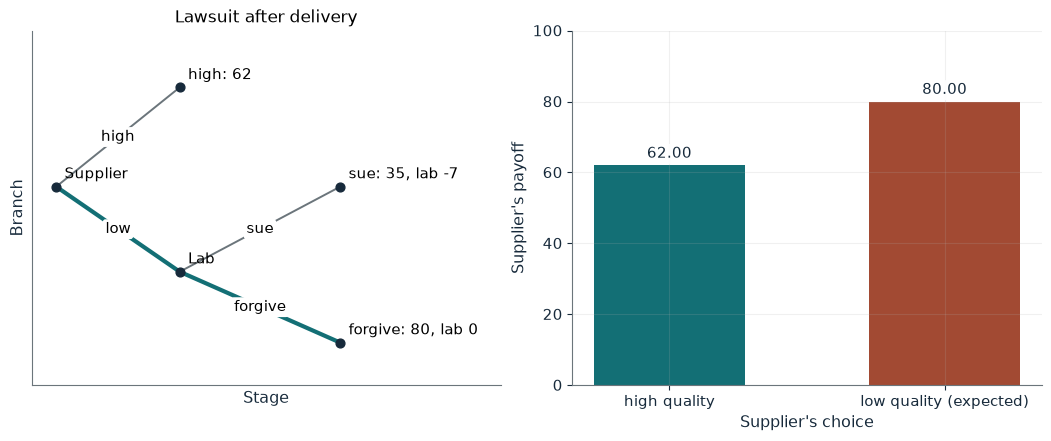

Lab's net from suing              -7
Supplier, high quality            62.00
Supplier, low quality (expected)  80.00
Supplier's choice                 Low quality
Deterrence threshold p            0.40

Worked steps:
  1. Lab's net from suing = 45 - 52 = -7, below 0 from forgiving, so it forgives
  2. High quality: 80 - 18 = 62
  3. Low quality: 80, because the penalty is never collected
  4. 62 < 80: low quality

Suing would win 45 but cost 52, so the lab's net is 45 - 52 = -7 and it forgives. The supplier therefore compares 80 - 18 = 62 from high quality with 80 from low quality and cheats. Detection at 1.00 changes nothing, because a detected defect still goes unpunished.


In [2]:
show(escrow_picture(mech='lawsuit', p=1.0))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(escrow_picture, 'p', [0.2, 0.4, 0.6, 1.0], {'mech': 'escrow'}, ['Supplier, low quality (expected)', "Supplier's choice"])

p | Supplier, low quality (expected) | Supplier's choice
0.2 | 71.00 | Low quality
0.4 | 62.00 | Tie: indifferent at 62
0.6 | 53.00 | High quality
1.0 | 35.00 | High quality


Under a lawsuit the lab forgives, so the supplier cheats. With escrow, detection of 0.60 leaves low quality at 53, below 62; at exactly 0.40 the supplier is indifferent.

## 2. Credible commitment and sovereign default

A bond with face 150, an 8 percent safe rate and zero recovery:

$$q=\frac{0.70(150)}{1.08}=97.22, \qquad q=\frac{0.92(150)}{1.08}=127.78$$

Next period repayment leaves $180-150=30$ and default leaves $180-165=15$.

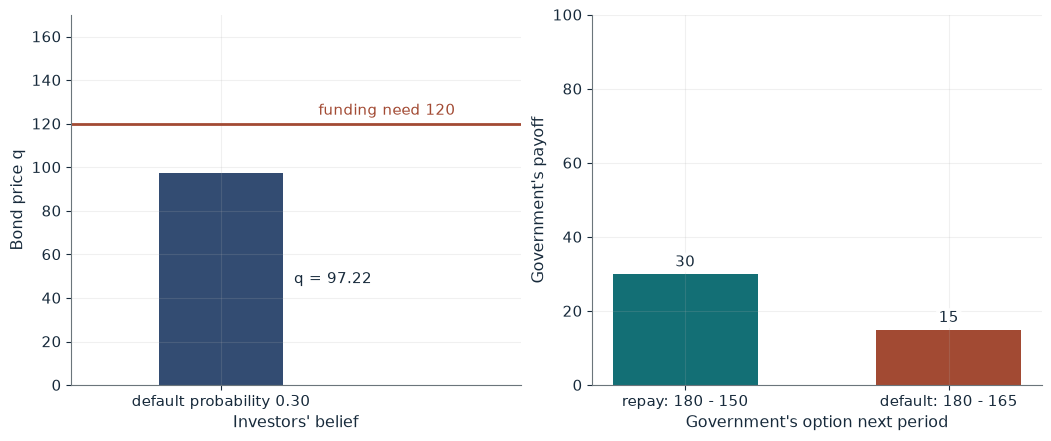

Bond price q             97.22
Funded (q at least 120)  no
Repay payoff             30
Default payoff           15
Repayment credible       yes

Worked steps:
  1. q = (1 - 0.30) x 150 / 1.08 = 105.00 / 1.08 = 97.22
  2. 97.22 < 120: not funded
  3. Repay: 180 - 150 = 30
  4. Default: 180 - 165 = 15
  5. 30 > 15

At default probability 0.30, the bond is worth (1 - 0.30) x 150 / 1.08 = 97.22, not enough to raise 120. Repaying leaves 30 against 15 from default, so the promise is credible.


In [4]:
show(bond_picture(pd=0.30, penalty=165))

Change one input, `penalty`, and hold the others at the book's values:

In [5]:
sweep(bond_picture, 'penalty', [100, 150, 165], {'pd': 0.08}, ['Bond price q', 'Default payoff', 'Repayment credible'])

penalty | Bond price q | Default payoff | Repayment credible
100 | 127.78 | 80 | no
150 | 127.78 | 30 | Tie: indifferent
165 | 127.78 | 15 | yes


At 0.30 the bond raises only 97.22 of the 120 needed. A low default belief of 0.08 funds the project, but it is justified only if the penalty makes repaying the better choice; with penalty 100, default leaves 80 > 30.

## 3. Time inconsistency: discretion versus commitment

The bank minimizes $L=\pi^2+0.5(\pi-\pi^e-2)^2$ after wages are set, so

$$\pi=\frac{\pi^e+2}{3}, \qquad L_D=1^2+0.5(0-2)^2=3, \qquad L_C=0^2+0.5(0-2)^2=2$$

The general reaction with ambition $k$ and weight $b$ is $\pi=b(\pi^e+k)/(1+b)$.

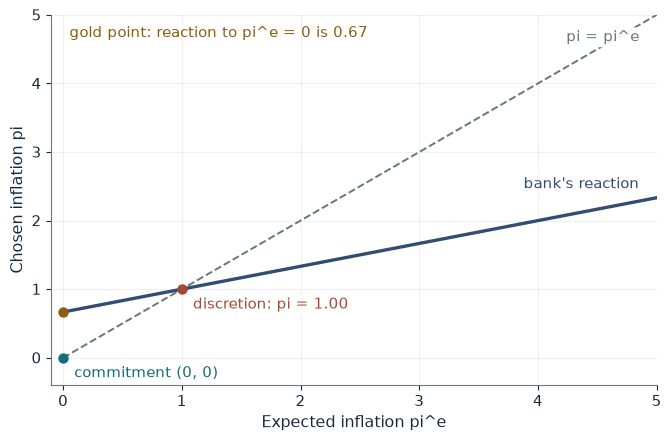

Reaction to pi^e = 0        0.6667
Discretionary inflation     1.00
Loss under discretion       3.0000
Loss under commitment       2.0000
Extra loss from discretion  1.0000

Worked steps:
  1. Reaction: pi = 0.50 x (pi^e + 2) / 1.50; at pi^e = 0, pi = 1.00 / 1.50 = 0.6667
  2. Equilibrium pi = pi^e: pi = 0.50 x 2 = 1.00
  3. L_D = 1.00^2 + 0.50 x (0 - 2)^2 = 1.0000 + 2.0000 = 3.0000
  4. L_C = 0^2 + 0.50 x (0 - 2)^2 = 2.0000

Once wages expect zero inflation, the bank's best response is 0.50 x 2 / 1.50 = 0.6667, so the zero promise is not time-consistent. In equilibrium pi = pi^e = 0.50 x 2 = 1.00 with output at its natural level. Loss is 3.0000 under discretion and 2.0000 under commitment: discretion adds 1.0000 with no lasting output gain.


In [6]:
show(policy_picture(k=2, b=0.5))

Change one input, `k`, and hold the others at the book's values:

In [7]:
sweep(policy_picture, 'k', [0, 1, 2, 3], {'b': 0.5}, ['Discretionary inflation', 'Loss under discretion', 'Loss under commitment'])

k | Discretionary inflation | Loss under discretion | Loss under commitment
0 | 0.00 | 0.0000 | 0.0000
1 | 0.50 | 0.7500 | 0.5000
2 | 1.00 | 3.0000 | 2.0000
3 | 1.50 | 6.7500 | 4.5000


Discretion produces inflation of 1 with output still at its natural level, and raises the loss from 2 to 3. With no output ambition (k = 0) the bias disappears.

## 4. Commitment-problem theory of war

A prize of 100; A wins with probability 0.65 today and 0.20 after B's program; costs 15 and 20.

$$w_A(1)=0.65(100)-15=50, \qquad w_B(2)=0.80(100)-20=60$$

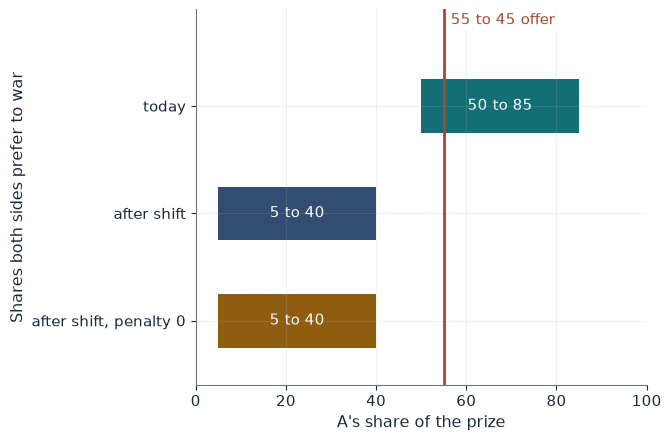

w_A(1)               50
w_B(1)               15
w_A(2)               5
w_B(2)               60
B's revision payoff  60
Deal survives        no

Worked steps:
  1. w_A(1) = 0.65 x 100 - 15 = 50; w_B(1) = 0.35 x 100 - 20 = 15
  2. w_A(2) = 0.20 x 100 - 15 = 5; w_B(2) = 0.80 x 100 - 20 = 60
  3. B's revision payoff = 60 - 0 = 60
  4. 60 > 45: B revises

Today war gives A 0.65 x 100 - 15 = 50 and B 15, so any share for A between 50 and 85 beats fighting. If A's future win chance is 0.20, B's future war payoff is 0.80 x 100 - 20 = 60. After the shift B can get 60 - 0 = 60 by forcing a revision, more than the 45 it is promised, so the 55 to 45 division cannot survive. A could keep at most 100 - 60 = 40 later, below its war payoff of 50 today, so A prefers to fight now.


In [8]:
show(war_picture(pa2=0.20, g=0))

Change one input, `g`, and hold the others at the book's values:

In [9]:
sweep(war_picture, 'g', [0, 10, 20, 30], {'pa2': 0.2}, ["B's revision payoff", 'Deal survives'])

g | B's revision payoff | Deal survives
0 | 60 | no
10 | 50 | no
20 | 40 | yes
30 | 30 | yes


Without a guarantor B will later demand 60, so the 55 to 45 deal cannot hold. A credible penalty of 20 lowers B's revision payoff to 60 - 20 = 40 < 45, and the deal survives.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

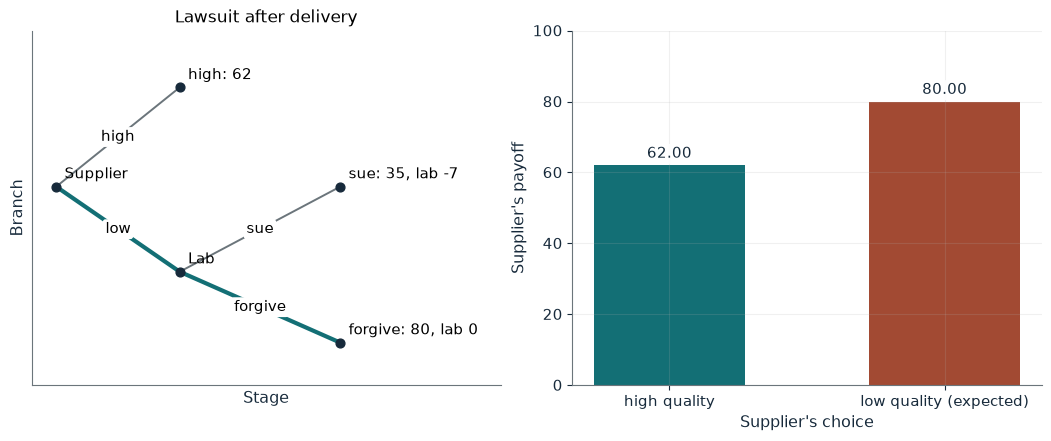

Lab's net from suing              -7
Supplier, high quality            62.00
Supplier, low quality (expected)  80.00
Supplier's choice                 Low quality
Deterrence threshold p            0.40

Worked steps:
  1. Lab's net from suing = 45 - 52 = -7, below 0 from forgiving, so it forgives
  2. High quality: 80 - 18 = 62
  3. Low quality: 80, because the penalty is never collected
  4. 62 < 80: low quality

Suing would win 45 but cost 52, so the lab's net is 45 - 52 = -7 and it forgives. The supplier therefore compares 80 - 18 = 62 from high quality with 80 from low quality and cheats. Detection at 1.00 changes nothing, because a detected defect still goes unpunished.


In [10]:
show(escrow_picture(mech='lawsuit', p=1.0))

## Practice

**1.** Under escrow, what is the minimum detection rate that deters low quality?

<details><summary>Answer</summary>

62 >= 80 - 45p gives p >= 18 / 45 = 0.40; at p = 0.60 low quality yields 80 - 27 = 53 < 62.

</details>

**2.** With default penalty 100, is repayment credible?

<details><summary>Answer</summary>

Default leaves 180 - 100 = 80, more than the 30 from repaying, so no; investors should not believe a low default probability.

</details>

**3.** Can any guarantor penalty below 15 save the 55 to 45 deal when A's future win chance is 0.20?

<details><summary>Answer</summary>

No: B's revision payoff 60 - g stays above 45 for every g below 15.

</details>